# Consulta piloto de curvas de luz TESS

## Proyecto

**Descubrimiento de ecuaciones dinámicas en estrellas variables mediante TESS, SINDy y Neural ODE**

## Objetivo

Consultar la disponibilidad de curvas de luz TESS para tres objetos prototipo:

1. RR Lyr, representante de RRab.
2. delta Sct, representante de estrellas Delta Scuti.
3. W UMa, representante de binarias eclipsantes de contacto.

En esta etapa se consultarán metadatos. No se realizará una descarga masiva.

## Criterio

Primero se inspeccionarán sectores, autores, cadencias y tiempos de exposición.
Después se seleccionará un único producto por objeto para una descarga controlada.

In [1]:
import sys
from pathlib import Path

import astropy
import astroquery
import lightkurve as lk
import numpy as np
import pandas as pd

print(f"Python: {sys.version.split()[0]}")
print(f"Lightkurve: {lk.__version__}")
print(f"Astropy: {astropy.__version__}")
print(f"Astroquery: {astroquery.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

Python: 3.11.17
Lightkurve: 2.6.0
Astropy: 8.0.2
Astroquery: 0.4.11
Pandas: 2.3.3
NumPy: 2.4.6


C:\Users\Maor\miniforge3\envs\tess-dynamics\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
project_root = Path.cwd().parent

expected_folders = [
    "01_literature",
    "05_notebooks",
    "07_data",
    "08_results",
]

print("Directorio del notebook:", Path.cwd())
print("Raíz estimada del proyecto:", project_root)

for folder in expected_folders:
    folder_path = project_root / folder
    print(f"{folder}: {folder_path.exists()}")

Directorio del notebook: C:\Users\Maor\Documents\TESS_Dynamical_Equations\05_notebooks
Raíz estimada del proyecto: C:\Users\Maor\Documents\TESS_Dynamical_Equations
01_literature: True
05_notebooks: True
07_data: True
08_results: True


In [5]:
prototype_targets = {
    "RRab": "RR Lyr",
    "DSCT": "delta Sct",
    "EW": "W UMa",
}

search_results = {}

for variability_class, target_name in prototype_targets.items():
    print("=" * 80)
    print(f"Clase: {variability_class}")
    print(f"Objeto consultado: {target_name}")

    result = lk.search_lightcurve(
        target_name,
        mission="TESS",
    )

    search_results[variability_class] = result

    print(f"Productos encontrados: {len(result)}")
    print(result)
    print()

Clase: RRab
Objeto consultado: RR Lyr
Productos encontrados: 6
SearchResult containing 6 data products.

 #     mission     year   author  exptime target_name distance
                                     s                 arcsec 
--- -------------- ---- --------- ------- ----------- --------
  0 TESS Sector 14 2019      SPOC     120   159717514      0.0
  1 TESS Sector 40 2021      SPOC     120   159717514      0.0
  2 TESS Sector 41 2021      SPOC     120   159717514      0.0
  3 TESS Sector 14 2019 TESS-SPOC    1800   159717514      0.0
  4 TESS Sector 40 2021 TESS-SPOC     600   159717514      0.0
  5 TESS Sector 41 2021 TESS-SPOC     600   159717514      0.0

Clase: DSCT
Objeto consultado: delta Sct
Productos encontrados: 4
SearchResult containing 4 data products.

 #     mission     year   author  exptime target_name distance
                                     s                 arcsec 
--- -------------- ---- --------- ------- ----------- --------
  0 TESS Sector 80 2024      S

In [6]:
def summarize_search_result(
    search_result,
    variability_class,
    target_name,
):
    """
    Convierte un SearchResult de Lightkurve en una tabla compacta.
    """
    if len(search_result) == 0:
        return pd.DataFrame()

    table = search_result.table.to_pandas().copy()

    desired_columns = [
        "target_name",
        "mission",
        "author",
        "exptime",
        "distance",
        "productFilename",
    ]

    available_columns = [
        column
        for column in desired_columns
        if column in table.columns
    ]

    summary = table[available_columns].copy()

    summary.insert(
        0,
        "variability_class",
        variability_class,
    )

    summary.insert(
        1,
        "query_name",
        target_name,
    )

    return summary

In [7]:
summary_tables = []

for variability_class, target_name in prototype_targets.items():
    summary = summarize_search_result(
        search_result=search_results[variability_class],
        variability_class=variability_class,
        target_name=target_name,
    )

    if not summary.empty:
        summary_tables.append(summary)

if summary_tables:
    tess_search_summary = pd.concat(
        summary_tables,
        ignore_index=True,
    )
else:
    tess_search_summary = pd.DataFrame()

print("Número total de productos resumidos:", len(tess_search_summary))

tess_search_summary.head(20)

Número total de productos resumidos: 27


,variability_class,query_name,target_name,mission,author,exptime,distance,productFilename
0,RRab,RR Lyr,159717514,TESS Sector 14,SPOC,120.0,0.0,tess2019198215352-s0014-0000000159717514-0150-...
1,RRab,RR Lyr,159717514,TESS Sector 40,SPOC,120.0,0.0,tess2021175071901-s0040-0000000159717514-0211-...
2,RRab,RR Lyr,159717514,TESS Sector 41,SPOC,120.0,0.0,tess2021204101404-s0041-0000000159717514-0212-...
3,RRab,RR Lyr,159717514,TESS Sector 14,TESS-SPOC,1800.0,0.0,hlsp_tess-spoc_tess_phot_0000000159717514-s001...
4,RRab,RR Lyr,159717514,TESS Sector 40,TESS-SPOC,600.0,0.0,hlsp_tess-spoc_tess_phot_0000000159717514-s004...
5,RRab,RR Lyr,159717514,TESS Sector 41,TESS-SPOC,600.0,0.0,hlsp_tess-spoc_tess_phot_0000000159717514-s004...
6,DSCT,delta Sct,162499828,TESS Sector 80,SPOC,120.0,0.0,tess2024170053053-s0080-0000000162499828-0275-...
7,DSCT,delta Sct,162499828,TESS Sector 80,TESS-SPOC,200.0,0.0,hlsp_tess-spoc_tess_phot_0000000162499828-s008...
8,DSCT,delta Sct,162499828,TESS Sector 80,QLP,200.0,0.0,hlsp_qlp_tess_ffi_s0080-0000000162499828_tess_...
9,DSCT,delta Sct,162499828,TESS Sector 80,TARS,200.0,0.0,hlsp_tars_tess_ffi_s0080-0000000162499828_tess...


In [8]:
if tess_search_summary.empty:
    print("No se encontraron productos para resumir.")
else:
    group_columns = [
        column
        for column in [
            "variability_class",
            "author",
            "exptime",
        ]
        if column in tess_search_summary.columns
    ]

    availability_summary = (
        tess_search_summary
        .groupby(
            group_columns,
            dropna=False,
        )
        .size()
        .reset_index(name="product_count")
        .sort_values(
            by=[
                "variability_class",
                "product_count",
            ],
            ascending=[True, False],
        )
    )

    display(availability_summary)

,variability_class,author,exptime,product_count
0,DSCT,QLP,200.0,1
1,DSCT,SPOC,120.0,1
2,DSCT,TARS,200.0,1
3,DSCT,TESS-SPOC,200.0,1
8,EW,SPOC,120.0,3
9,EW,TARS,200.0,2
10,EW,TARS,600.0,2
11,EW,TARS,1800.0,2
4,EW,QLP,200.0,1
5,EW,QLP,600.0,1


In [9]:
catalog_directory = project_root / "07_data" / "catalog"
catalog_directory.mkdir(
    parents=True,
    exist_ok=True,
)

search_summary_path = (
    catalog_directory
    / "prototype_tess_search_results.csv"
)

availability_path = (
    catalog_directory
    / "prototype_tess_availability_summary.csv"
)

tess_search_summary.to_csv(
    search_summary_path,
    index=False,
)

if not tess_search_summary.empty:
    availability_summary.to_csv(
        availability_path,
        index=False,
    )

print("Archivo guardado:")
print(search_summary_path)

if not tess_search_summary.empty:
    print(availability_path)

Archivo guardado:
C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\catalog\prototype_tess_search_results.csv
C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\catalog\prototype_tess_availability_summary.csv


In [10]:
for variability_class, result in search_results.items():
    print(
        f"{variability_class}: "
        f"{len(result)} productos encontrados"
    )

assert all(
    variability_class in search_results
    for variability_class in ["RRab", "DSCT", "EW"]
)

assert search_summary_path.exists()

print("CONSULTA PILOTO DE TESS COMPLETADA")

RRab: 6 productos encontrados
DSCT: 4 productos encontrados
EW: 17 productos encontrados
CONSULTA PILOTO DE TESS COMPLETADA


In [11]:
print(availability_summary.to_string(index=False))

variability_class    author  exptime  product_count
             DSCT       QLP    200.0              1
             DSCT      SPOC    120.0              1
             DSCT      TARS    200.0              1
             DSCT TESS-SPOC    200.0              1
               EW      SPOC    120.0              3
               EW      TARS    200.0              2
               EW      TARS    600.0              2
               EW      TARS   1800.0              2
               EW       QLP    200.0              1
               EW       QLP    600.0              1
               EW       QLP   1800.0              1
               EW      SPOC     20.0              1
               EW   TEQUILA   1800.0              1
               EW TESS-SPOC    200.0              1
               EW TESS-SPOC    600.0              1
               EW TESS-SPOC   1800.0              1
             RRab      SPOC    120.0              3
             RRab TESS-SPOC    600.0              2
            

In [13]:
print(
    tess_search_summary.head(20).to_string(index=False)
)

variability_class query_name target_name        mission    author  exptime  distance                                                 productFilename
             RRab     RR Lyr   159717514 TESS Sector 14      SPOC    120.0       0.0         tess2019198215352-s0014-0000000159717514-0150-s_lc.fits
             RRab     RR Lyr   159717514 TESS Sector 40      SPOC    120.0       0.0         tess2021175071901-s0040-0000000159717514-0211-s_lc.fits
             RRab     RR Lyr   159717514 TESS Sector 41      SPOC    120.0       0.0         tess2021204101404-s0041-0000000159717514-0212-s_lc.fits
             RRab     RR Lyr   159717514 TESS Sector 14 TESS-SPOC   1800.0       0.0 hlsp_tess-spoc_tess_phot_0000000159717514-s0014_tess_v1_lc.fits
             RRab     RR Lyr   159717514 TESS Sector 40 TESS-SPOC    600.0       0.0 hlsp_tess-spoc_tess_phot_0000000159717514-s0040_tess_v1_lc.fits
             RRab     RR Lyr   159717514 TESS Sector 41 TESS-SPOC    600.0       0.0 hlsp_tess-spoc_tess_p

## Selección controlada del piloto

Se selecciona un producto SPOC de 120 segundos por clase:

- RRab: RR Lyr, TIC 159717514, sector 14.
- DSCT: delta Sct, TIC 162499828, sector 80.
- EW: W UMa, TIC 446127290, sector 74.

La cadencia nominal común de 120 segundos permite una comparación inicial
sin introducir diferencias debidas al tiempo de exposición.

Se conservarán SAP y PDCSAP por separado. No se concatenarán sectores.

In [14]:
pilot_selection = pd.DataFrame(
    [
        {
            "variability_class": "RRab",
            "query_name": "RR Lyr",
            "tic_id": 159717514,
            "sector": 14,
            "author": "SPOC",
            "exptime_seconds": 120.0,
        },
        {
            "variability_class": "DSCT",
            "query_name": "delta Sct",
            "tic_id": 162499828,
            "sector": 80,
            "author": "SPOC",
            "exptime_seconds": 120.0,
        },
        {
            "variability_class": "EW",
            "query_name": "W UMa",
            "tic_id": 446127290,
            "sector": 74,
            "author": "SPOC",
            "exptime_seconds": 120.0,
        },
    ]
)

display(pilot_selection)

,variability_class,query_name,tic_id,sector,author,exptime_seconds
0,RRab,RR Lyr,159717514,14,SPOC,120.0
1,DSCT,delta Sct,162499828,80,SPOC,120.0
2,EW,W UMa,446127290,74,SPOC,120.0


In [15]:
pilot_selection_path = (
    project_root
    / "07_data"
    / "catalog"
    / "pilot_product_selection.csv"
)

pilot_selection.to_csv(
    pilot_selection_path,
    index=False,
)

print("Selección guardada:", pilot_selection_path)
print("Archivo existente:", pilot_selection_path.exists())

Selección guardada: C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\catalog\pilot_product_selection.csv
Archivo existente: True


In [16]:
raw_pilot_directory = (
    project_root
    / "07_data"
    / "raw"
    / "pilot"
)

raw_pilot_directory.mkdir(
    parents=True,
    exist_ok=True,
)

print("Directorio de descarga:", raw_pilot_directory)
print("Directorio existente:", raw_pilot_directory.exists())


Directorio de descarga: C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\raw\pilot
Directorio existente: True


In [19]:
def search_selected_spoc_product(
    query_name,
    sector,
    expected_exptime=120.0,
):
    result = lk.search_lightcurve(
        query_name,
        mission="TESS",
        author="SPOC",
        sector=sector,
        cadence="short",
    )

    if len(result) == 0:
        raise RuntimeError(
            f"No se encontró un producto SPOC para "
            f"{query_name}, sector {sector}."
        )

    result_table = result.table.to_pandas().copy()

    if "exptime" in result_table.columns:
        matching_mask = np.isclose(
            result_table["exptime"].astype(float),
            expected_exptime,
        )

        matching_indices = np.flatnonzero(matching_mask)

        if len(matching_indices) == 0:
            raise RuntimeError(
                f"Se encontraron productos para {query_name}, "
                f"pero ninguno tiene exposición de "
                f"{expected_exptime} segundos."
            )

        result = result[matching_indices]

    return result

In [20]:
selected_search_results = {}

for row in pilot_selection.itertuples(index=False):
    result = search_selected_spoc_product(
        query_name=row.query_name,
        sector=int(row.sector),
        expected_exptime=float(row.exptime_seconds),
    )

    selected_search_results[row.variability_class] = result

    print("=" * 70)
    print(
        f"{row.variability_class} | "
        f"{row.query_name} | "
        f"sector {row.sector}"
    )
    print(result)

RRab | RR Lyr | sector 14
SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 14 2019   SPOC     120   159717514      0.0
DSCT | delta Sct | sector 80
SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 80 2024   SPOC     120   162499828      0.0
EW | W UMa | sector 74
SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 74 2024   SPOC     120   446127290      0.0


In [21]:
pilot_lightcurves = {}

for variability_class, result in selected_search_results.items():
    print("=" * 70)
    print(f"Descargando: {variability_class}")

    sap_lightcurve = result.download(
        download_dir=str(raw_pilot_directory),
        flux_column="sap_flux",
        quality_bitmask="none",
    )

    pdcsap_lightcurve = result.download(
        download_dir=str(raw_pilot_directory),
        flux_column="pdcsap_flux",
        quality_bitmask="none",
    )

    if sap_lightcurve is None or pdcsap_lightcurve is None:
        raise RuntimeError(
            f"No se pudo descargar {variability_class}."
        )

    pilot_lightcurves[variability_class] = {
        "SAP": sap_lightcurve,
        "PDCSAP": pdcsap_lightcurve,
    }

    print("Puntos SAP:", len(sap_lightcurve))
    print("Puntos PDCSAP:", len(pdcsap_lightcurve))
    print("Sector:", sap_lightcurve.meta.get("SECTOR"))
    print("TIC:", sap_lightcurve.meta.get("TARGETID"))

Descargando: RRab
Puntos SAP: 18654
Puntos PDCSAP: 18654
Sector: 14
TIC: 159717514
Descargando: DSCT
Puntos SAP: 18597
Puntos PDCSAP: 18597
Sector: 80
TIC: 162499828
Descargando: EW
Puntos SAP: 18810
Puntos PDCSAP: 18810
Sector: 74
TIC: 446127290


In [22]:
expected_tic_ids = {
    "RRab": 159717514,
    "DSCT": 162499828,
    "EW": 446127290,
}

expected_sectors = {
    "RRab": 14,
    "DSCT": 80,
    "EW": 74,
}

for variability_class, flux_versions in pilot_lightcurves.items():
    sap_lc = flux_versions["SAP"]
    pdcsap_lc = flux_versions["PDCSAP"]

    observed_tic = int(sap_lc.meta["TARGETID"])
    observed_sector = int(sap_lc.meta["SECTOR"])

    assert observed_tic == expected_tic_ids[variability_class]
    assert observed_sector == expected_sectors[variability_class]
    assert len(sap_lc) == len(pdcsap_lc)

    print(
        f"{variability_class}: "
        f"TIC {observed_tic}, "
        f"sector {observed_sector}, "
        f"{len(sap_lc)} cadencias"
    )

print("DESCARGA CONTROLADA VALIDADA")

RRab: TIC 159717514, sector 14, 18654 cadencias
DSCT: TIC 162499828, sector 80, 18597 cadencias
EW: TIC 446127290, sector 74, 18810 cadencias
DESCARGA CONTROLADA VALIDADA


In [24]:
def diagnose_lightcurve(
    lightcurve,
    variability_class,
    flux_type,
):
    time_values = np.asarray(
        lightcurve.time.value,
        dtype=float,
    )

    flux_values = np.asarray(
        lightcurve.flux.value,
        dtype=float,
    )

    if lightcurve.flux_err is not None:
        flux_error_values = np.asarray(
            lightcurve.flux_err.value,
            dtype=float,
        )
    else:
        flux_error_values = np.full(
            len(lightcurve),
            np.nan,
        )

    quality_values = np.asarray(
        lightcurve.quality,
        dtype=np.int64,
    )

    finite_time = np.isfinite(time_values)
    finite_flux = np.isfinite(flux_values)
    finite_flux_error = np.isfinite(flux_error_values)

    valid_times = np.sort(time_values[finite_time])

    if len(valid_times) >= 2:
        time_differences = np.diff(valid_times)
        positive_differences = time_differences[
            time_differences > 0
        ]

        median_cadence_days = (
            np.median(positive_differences)
            if len(positive_differences) > 0
            else np.nan
        )

        duration_days = (
            valid_times[-1] - valid_times[0]
        )
    else:
        median_cadence_days = np.nan
        duration_days = np.nan

    return {
        "variability_class": variability_class,
        "flux_type": flux_type,
        "tic_id": lightcurve.meta.get("TARGETID"),
        "sector": lightcurve.meta.get("SECTOR"),
        "author": lightcurve.meta.get("AUTHOR"),
        "n_total": len(lightcurve),
        "n_finite_time": int(finite_time.sum()),
        "n_finite_flux": int(finite_flux.sum()),
        "n_finite_flux_error": int(
            finite_flux_error.sum()
        ),
        "n_quality_zero": int(
            np.sum(quality_values == 0)
        ),
        "n_quality_nonzero": int(
            np.sum(quality_values != 0)
        ),
        "duration_days": duration_days,
        "median_cadence_seconds": (
            median_cadence_days * 86400.0
        ),
        "flux_median": float(
            np.nanmedian(flux_values)
        ),
        "flux_std": float(
            np.nanstd(flux_values)
        ),
    }

In [28]:
def diagnose_lightcurve(
    lightcurve,
    variability_class,
    flux_type,
):
    time_values = np.asarray(
        lightcurve.time.value,
        dtype=float,
    )

    flux_values = np.asarray(
        lightcurve.flux.value,
        dtype=float,
    )

    if lightcurve.flux_err is not None:
        flux_error_values = np.asarray(
            lightcurve.flux_err.value,
            dtype=float,
        )
    else:
        flux_error_values = np.full(
            len(lightcurve),
            np.nan,
        )

    quality_values = np.asarray(
        lightcurve.quality,
        dtype=np.int64,
    )

    finite_time = np.isfinite(time_values)
    finite_flux = np.isfinite(flux_values)
    finite_flux_error = np.isfinite(flux_error_values)

    valid_times = np.sort(time_values[finite_time])

    if len(valid_times) >= 2:
        time_differences = np.diff(valid_times)
        positive_differences = time_differences[
            time_differences > 0
        ]

        median_cadence_days = (
            np.median(positive_differences)
            if len(positive_differences) > 0
            else np.nan
        )

        duration_days = valid_times[-1] - valid_times[0]
    else:
        median_cadence_days = np.nan
        duration_days = np.nan

    return {
        "variability_class": variability_class,
        "flux_type": flux_type,
        "tic_id": lightcurve.meta.get("TARGETID"),
        "sector": lightcurve.meta.get("SECTOR"),
        "author": lightcurve.meta.get("AUTHOR"),
        "n_total": len(lightcurve),
        "n_finite_time": int(finite_time.sum()),
        "n_finite_flux": int(finite_flux.sum()),
        "n_finite_flux_error": int(finite_flux_error.sum()),
        "n_quality_zero": int(np.sum(quality_values == 0)),
        "n_quality_nonzero": int(np.sum(quality_values != 0)),
        "duration_days": float(duration_days),
        "median_cadence_seconds": float(
            median_cadence_days * 86400.0
        ),
        "flux_median": float(np.nanmedian(flux_values)),
        "flux_std": float(np.nanstd(flux_values)),
    }


diagnostic_rows = []

for variability_class, flux_versions in pilot_lightcurves.items():
    for flux_type, lightcurve in flux_versions.items():
        diagnostic_rows.append(
            diagnose_lightcurve(
                lightcurve=lightcurve,
                variability_class=variability_class,
                flux_type=flux_type,
            )
        )

pilot_diagnostics = pd.DataFrame(diagnostic_rows)

print(pilot_diagnostics.to_string(index=False))

variability_class flux_type    tic_id  sector author  n_total  n_finite_time  n_finite_flux  n_finite_flux_error  n_quality_zero  n_quality_nonzero  duration_days  median_cadence_seconds  flux_median     flux_std
             RRab       SAP 159717514      14   SPOC    18654          18654          18618                18618           18292                362      26.855500              120.000271 1.105363e+05 17757.000750
             RRab    PDCSAP 159717514      14   SPOC    18654          18654          18424                18424           18292                362      26.855500              120.000271 1.401300e+04 29202.417941
             DSCT       SAP 162499828      80   SPOC    18597          18597          17230                17230           12590               6007      26.452802              120.000669 2.854794e+06 83094.395154
             DSCT    PDCSAP 162499828      80   SPOC    18597          18597          12590                12590           12590               6007 

In [29]:
pilot_diagnostics_path = (
    project_root
    / "08_results"
    / "tables"
    / "pilot_lightcurve_diagnostics.csv"
)

pilot_diagnostics_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

pilot_diagnostics.to_csv(
    pilot_diagnostics_path,
    index=False,
)

print("Diagnóstico guardado:", pilot_diagnostics_path)
print("Archivo existente:", pilot_diagnostics_path.exists())

Diagnóstico guardado: C:\Users\Maor\Documents\TESS_Dynamical_Equations\08_results\tables\pilot_lightcurve_diagnostics.csv
Archivo existente: True


In [30]:
def build_common_quality_mask(sap_lc, pdcsap_lc):
    """
    Construye una máscara común para comparar SAP y PDCSAP usando
    exactamente las mismas cadencias.

    Criterios:
    - tiempo finito;
    - SAP finito;
    - PDCSAP finito;
    - quality == 0.
    """
    sap_time = np.asarray(
        sap_lc.time.value,
        dtype=float,
    )

    pdcsap_time = np.asarray(
        pdcsap_lc.time.value,
        dtype=float,
    )

    sap_flux = np.asarray(
        sap_lc.flux.value,
        dtype=float,
    )

    pdcsap_flux = np.asarray(
        pdcsap_lc.flux.value,
        dtype=float,
    )

    quality = np.asarray(
        sap_lc.quality,
        dtype=np.int64,
    )

    if len(sap_lc) != len(pdcsap_lc):
        raise ValueError(
            "SAP y PDCSAP no tienen la misma longitud."
        )

    if not np.allclose(
        sap_time,
        pdcsap_time,
        equal_nan=True,
    ):
        raise ValueError(
            "SAP y PDCSAP no comparten los mismos tiempos."
        )

    common_mask = (
        np.isfinite(sap_time)
        & np.isfinite(sap_flux)
        & np.isfinite(pdcsap_flux)
        & (quality == 0)
    )

    return common_mask

In [31]:
clean_pilot_data = {}
cleaning_rows = []

for variability_class, flux_versions in pilot_lightcurves.items():
    sap_lc = flux_versions["SAP"]
    pdcsap_lc = flux_versions["PDCSAP"]

    common_mask = build_common_quality_mask(
        sap_lc=sap_lc,
        pdcsap_lc=pdcsap_lc,
    )

    time_values = np.asarray(
        sap_lc.time.value,
        dtype=float,
    )[common_mask]

    sap_flux = np.asarray(
        sap_lc.flux.value,
        dtype=float,
    )[common_mask]

    pdcsap_flux = np.asarray(
        pdcsap_lc.flux.value,
        dtype=float,
    )[common_mask]

    sap_median = np.median(sap_flux)
    pdcsap_median = np.median(pdcsap_flux)

    if sap_median == 0 or pdcsap_median == 0:
        raise ValueError(
            f"Mediana nula en {variability_class}."
        )

    sap_normalized = (
        sap_flux / sap_median - 1.0
    )

    pdcsap_normalized = (
        pdcsap_flux / pdcsap_median - 1.0
    )

    clean_pilot_data[variability_class] = {
        "time": time_values,
        "sap_flux": sap_flux,
        "pdcsap_flux": pdcsap_flux,
        "sap_normalized": sap_normalized,
        "pdcsap_normalized": pdcsap_normalized,
        "common_mask": common_mask,
    }

    cleaning_rows.append(
        {
            "variability_class": variability_class,
            "n_original": len(sap_lc),
            "n_retained": int(common_mask.sum()),
            "n_removed": int(
                len(sap_lc) - common_mask.sum()
            ),
            "retained_fraction": float(
                common_mask.mean()
            ),
            "sap_relative_std": float(
                np.std(sap_normalized)
            ),
            "pdcsap_relative_std": float(
                np.std(pdcsap_normalized)
            ),
        }
    )

cleaning_summary = pd.DataFrame(cleaning_rows)

print(cleaning_summary.to_string(index=False))

variability_class  n_original  n_retained  n_removed  retained_fraction  sap_relative_std  pdcsap_relative_std
             RRab       18654       18292        362           0.980594          0.160500             2.125312
             DSCT       18597       12590       6007           0.676991          0.028945             0.030156
               EW       18810       12487       6323           0.663849          0.165114             0.201217


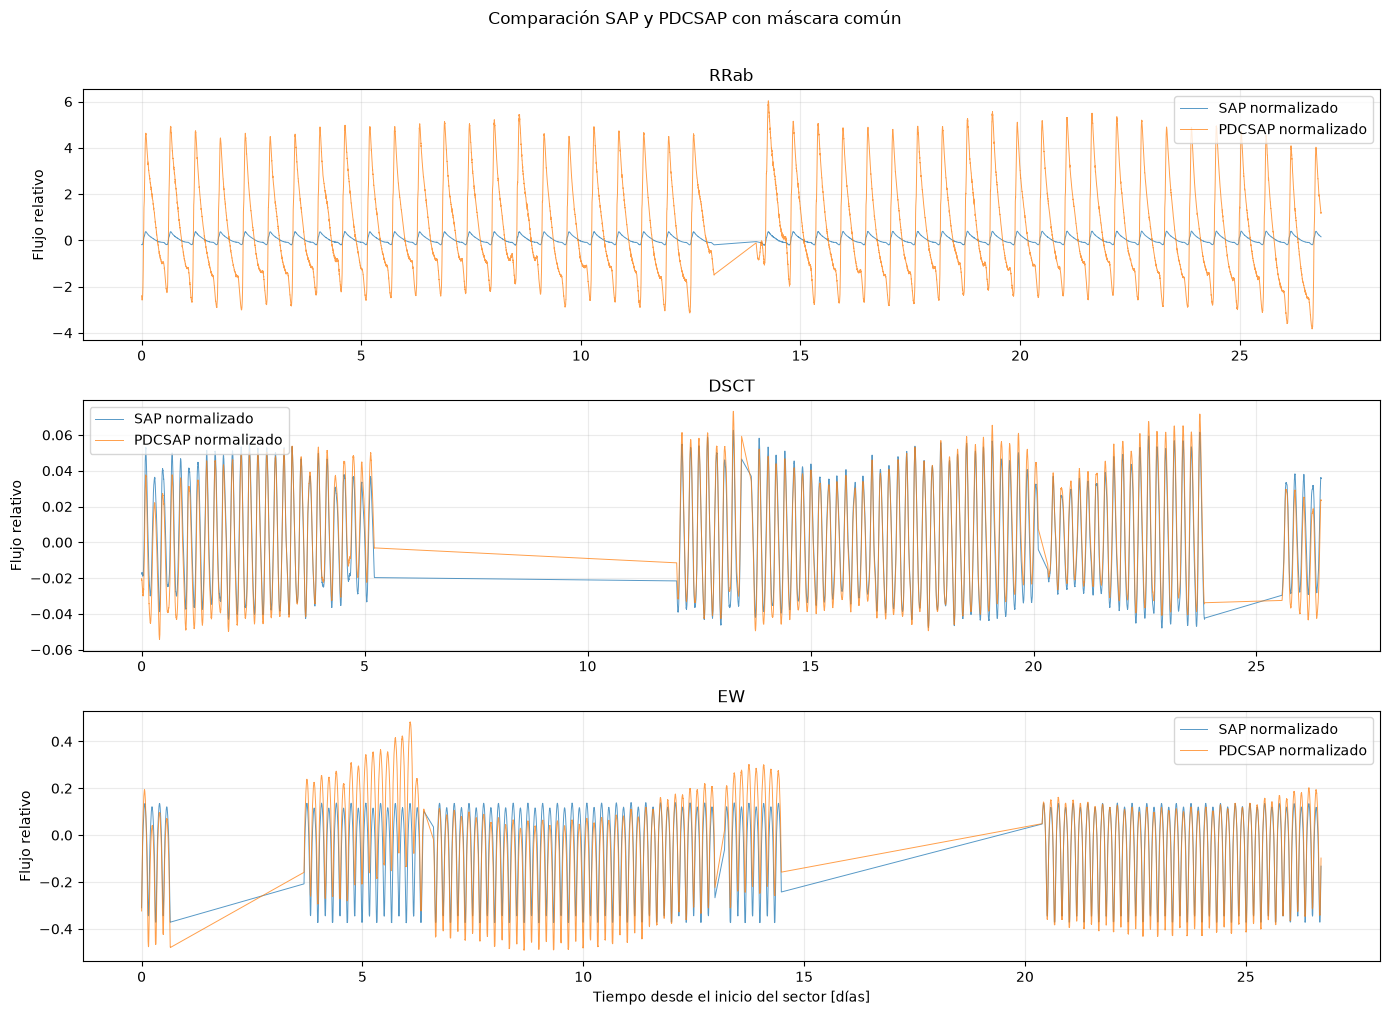

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 10),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    data = clean_pilot_data[variability_class]

    relative_time = (
        data["time"] - data["time"][0]
    )

    axis.plot(
        relative_time,
        data["sap_normalized"],
        linewidth=0.7,
        alpha=0.75,
        label="SAP normalizado",
    )

    axis.plot(
        relative_time,
        data["pdcsap_normalized"],
        linewidth=0.7,
        alpha=0.75,
        label="PDCSAP normalizado",
    )

    axis.set_title(variability_class)
    axis.set_ylabel("Flujo relativo")
    axis.grid(alpha=0.25)
    axis.legend()

axes[-1].set_xlabel(
    "Tiempo desde el inicio del sector [días]"
)

fig.suptitle(
    "Comparación SAP y PDCSAP con máscara común",
    y=1.01,
)

plt.tight_layout()
plt.show()

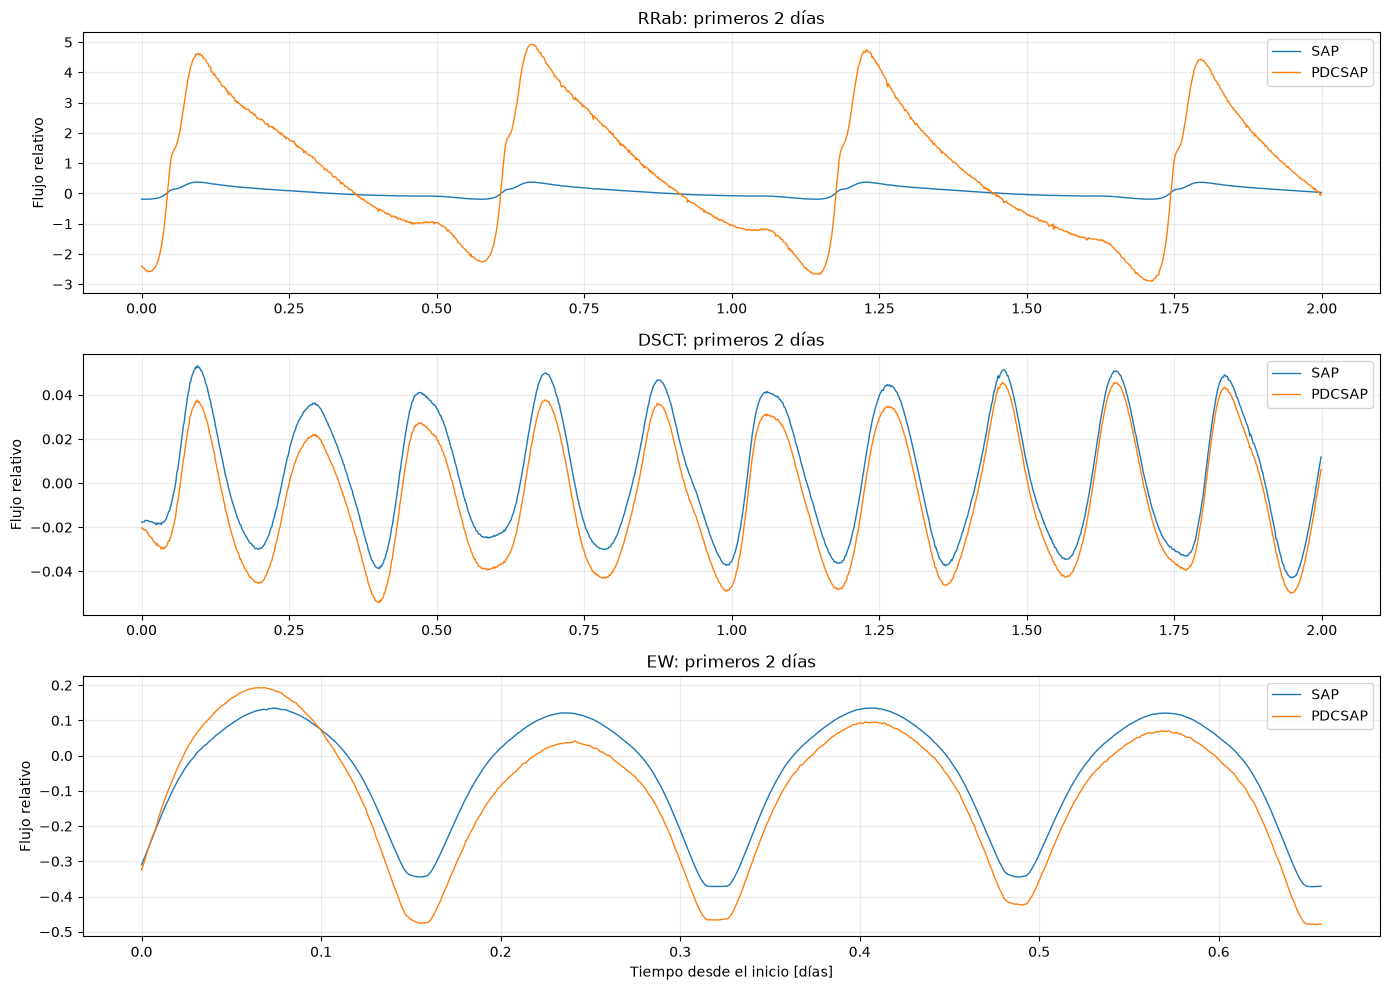

In [33]:
segment_duration_days = 2.0

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 10),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    data = clean_pilot_data[variability_class]

    relative_time = (
        data["time"] - data["time"][0]
    )

    segment_mask = (
        relative_time <= segment_duration_days
    )

    axis.plot(
        relative_time[segment_mask],
        data["sap_normalized"][segment_mask],
        linewidth=1.0,
        label="SAP",
    )

    axis.plot(
        relative_time[segment_mask],
        data["pdcsap_normalized"][segment_mask],
        linewidth=1.0,
        label="PDCSAP",
    )

    axis.set_title(
        f"{variability_class}: primeros "
        f"{segment_duration_days:.0f} días"
    )

    axis.set_ylabel("Flujo relativo")
    axis.grid(alpha=0.25)
    axis.legend()

axes[-1].set_xlabel(
    "Tiempo desde el inicio [días]"
)

plt.tight_layout()
plt.show()

In [34]:
gap_rows = []

for variability_class, data in clean_pilot_data.items():
    time_values = data["time"]

    time_differences_days = np.diff(
        time_values
    )

    median_cadence_days = np.median(
        time_differences_days[
            time_differences_days > 0
        ]
    )

    gap_threshold_days = (
        5.0 * median_cadence_days
    )

    gap_mask = (
        time_differences_days
        > gap_threshold_days
    )

    gap_sizes_days = (
        time_differences_days[gap_mask]
    )

    gap_rows.append(
        {
            "variability_class": variability_class,
            "median_cadence_seconds": float(
                median_cadence_days * 86400.0
            ),
            "gap_threshold_minutes": float(
                gap_threshold_days * 1440.0
            ),
            "n_detected_gaps": int(
                gap_mask.sum()
            ),
            "largest_gap_hours": float(
                np.max(gap_sizes_days) * 24.0
                if len(gap_sizes_days) > 0
                else 0.0
            ),
        }
    )

gap_summary = pd.DataFrame(gap_rows)

print(gap_summary.to_string(index=False))

variability_class  median_cadence_seconds  gap_threshold_minutes  n_detected_gaps  largest_gap_hours
             RRab              120.000271              10.000023                7          22.933294
             DSCT              119.999581               9.999965                4         162.667854
               EW              120.001877              10.000156                4         141.734685


In [35]:
cleaning_summary_path = (
    project_root
    / "08_results"
    / "tables"
    / "pilot_cleaning_summary.csv"
)

gap_summary_path = (
    project_root
    / "08_results"
    / "tables"
    / "pilot_gap_summary.csv"
)

cleaning_summary.to_csv(
    cleaning_summary_path,
    index=False,
)

gap_summary.to_csv(
    gap_summary_path,
    index=False,
)

print(cleaning_summary_path)
print(gap_summary_path)

C:\Users\Maor\Documents\TESS_Dynamical_Equations\08_results\tables\pilot_cleaning_summary.csv
C:\Users\Maor\Documents\TESS_Dynamical_Equations\08_results\tables\pilot_gap_summary.csv


In [36]:
processed_pilot_directory = (
    project_root
    / "07_data"
    / "processed"
    / "pilot_quality_zero"
)

processed_pilot_directory.mkdir(
    parents=True,
    exist_ok=True,
)

for variability_class, data in clean_pilot_data.items():
    output_table = pd.DataFrame(
        {
            "time_btjd": data["time"],
            "sap_flux": data["sap_flux"],
            "pdcsap_flux": data["pdcsap_flux"],
            "sap_normalized": (
                data["sap_normalized"]
            ),
            "pdcsap_normalized": (
                data["pdcsap_normalized"]
            ),
        }
    )

    output_path = (
        processed_pilot_directory
        / f"{variability_class.lower()}_pilot.csv"
    )

    output_table.to_csv(
        output_path,
        index=False,
    )

    print(
        variability_class,
        output_path,
        output_path.exists(),
    )

RRab C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\processed\pilot_quality_zero\rrab_pilot.csv True
DSCT C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\processed\pilot_quality_zero\dsct_pilot.csv True
EW C:\Users\Maor\Documents\TESS_Dynamical_Equations\07_data\processed\pilot_quality_zero\ew_pilot.csv True


In [37]:
def split_at_time_gaps(
    time_values,
    flux_values,
    gap_factor=5.0,
):
    """
    Divide una serie temporal en segmentos cuando el intervalo
    entre observaciones supera gap_factor veces la cadencia mediana.
    """
    time_values = np.asarray(time_values, dtype=float)
    flux_values = np.asarray(flux_values, dtype=float)

    time_differences = np.diff(time_values)

    positive_differences = time_differences[
        time_differences > 0
    ]

    median_cadence = np.median(
        positive_differences
    )

    gap_indices = np.flatnonzero(
        time_differences
        > gap_factor * median_cadence
    )

    split_indices = gap_indices + 1

    time_segments = np.split(
        time_values,
        split_indices,
    )

    flux_segments = np.split(
        flux_values,
        split_indices,
    )

    return list(zip(time_segments, flux_segments))

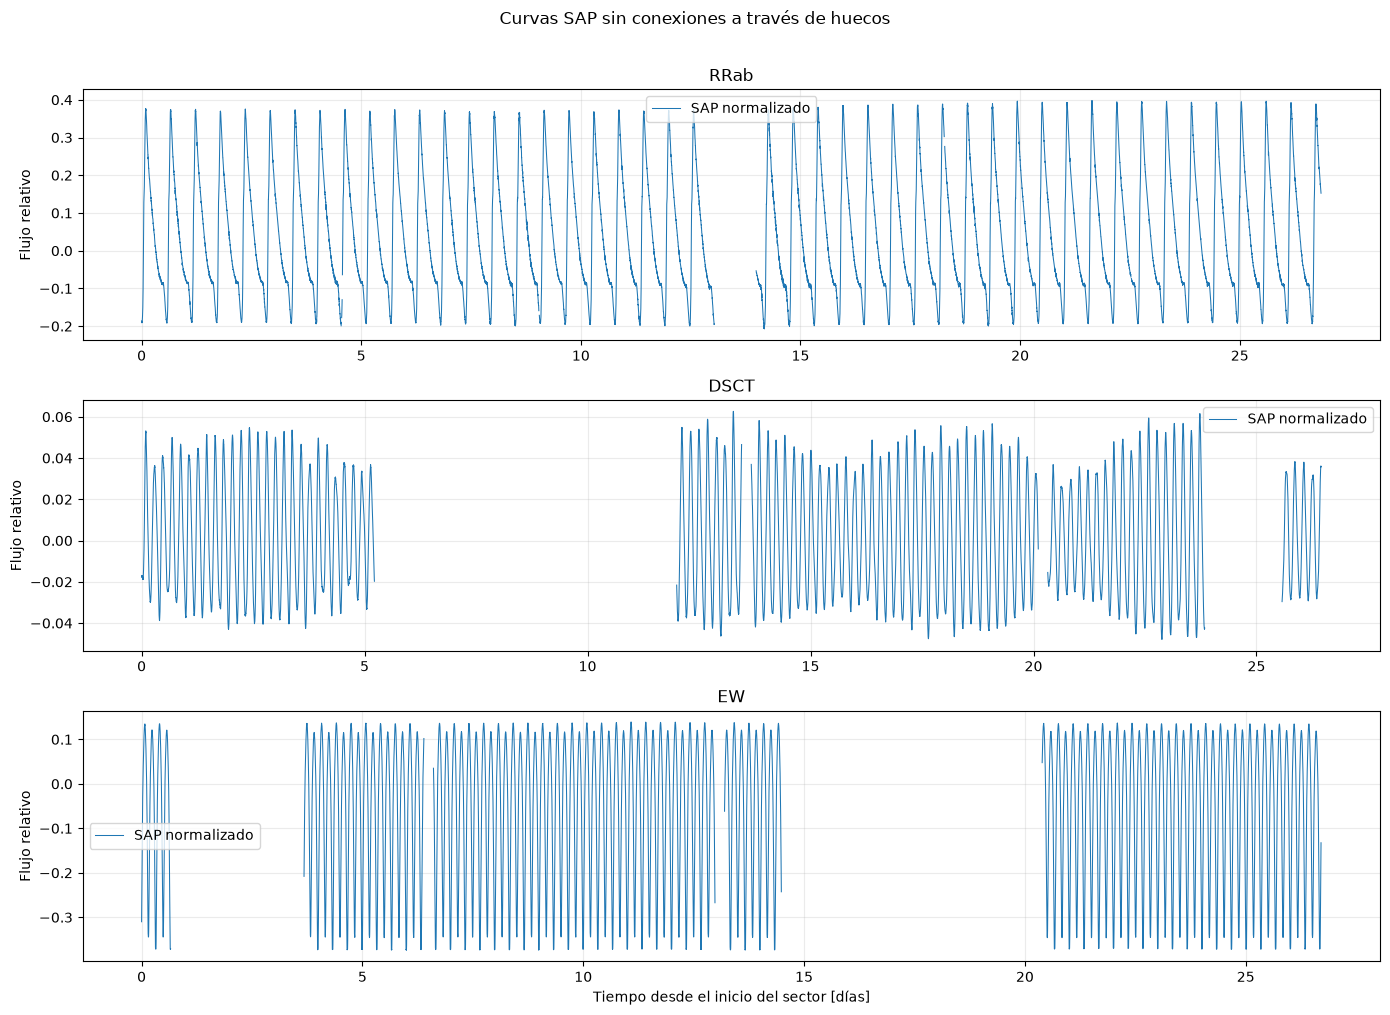

In [38]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 10),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    data = clean_pilot_data[variability_class]

    relative_time = (
        data["time"] - data["time"][0]
    )

    segments = split_at_time_gaps(
        time_values=relative_time,
        flux_values=data["sap_normalized"],
        gap_factor=5.0,
    )

    for segment_number, (
        segment_time,
        segment_flux,
    ) in enumerate(segments):
        axis.plot(
            segment_time,
            segment_flux,
            linewidth=0.75,
            color="tab:blue",
            label=(
                "SAP normalizado"
                if segment_number == 0
                else None
            ),
        )

    axis.set_title(variability_class)
    axis.set_ylabel("Flujo relativo")
    axis.grid(alpha=0.25)
    axis.legend()

axes[-1].set_xlabel(
    "Tiempo desde el inicio del sector [días]"
)

fig.suptitle(
    "Curvas SAP sin conexiones a través de huecos",
    y=1.01,
)

plt.tight_layout()
plt.show()

In [40]:
from astropy.timeseries import LombScargle
frequency_ranges = {
    "RRab": {
        "minimum_frequency": 0.5,
        "maximum_frequency": 10.0,
    },
    "DSCT": {
        "minimum_frequency": 4.0,
        "maximum_frequency": 80.0,
    },
    "EW": {
        "minimum_frequency": 0.2,
        "maximum_frequency": 10.0,
    },
}

In [41]:
periodogram_results = {}
period_rows = []

for variability_class, data in clean_pilot_data.items():
    time_values = np.asarray(
        data["time"],
        dtype=float,
    )

    flux_values = np.asarray(
        data["sap_normalized"],
        dtype=float,
    )

    time_values = (
        time_values - time_values[0]
    )

    finite_mask = (
        np.isfinite(time_values)
        & np.isfinite(flux_values)
    )

    time_values = time_values[finite_mask]
    flux_values = flux_values[finite_mask]

    flux_values = (
        flux_values - np.mean(flux_values)
    )

    minimum_frequency = frequency_ranges[
        variability_class
    ]["minimum_frequency"]

    maximum_frequency = frequency_ranges[
        variability_class
    ]["maximum_frequency"]

    lomb_scargle = LombScargle(
        time_values,
        flux_values,
        center_data=True,
        fit_mean=True,
    )

    frequency, power = lomb_scargle.autopower(
        minimum_frequency=minimum_frequency,
        maximum_frequency=maximum_frequency,
        samples_per_peak=15,
    )

    dominant_index = int(
        np.argmax(power)
    )

    dominant_frequency = float(
        frequency[dominant_index]
    )

    dominant_period = (
        1.0 / dominant_frequency
    )

    false_alarm_probability = float(
        lomb_scargle.false_alarm_probability(
            power[dominant_index]
        )
    )

    observed_duration = (
        time_values[-1] - time_values[0]
    )

    approximate_cycles = (
        observed_duration / dominant_period
    )

    periodogram_results[variability_class] = {
        "frequency": frequency,
        "power": power,
        "dominant_frequency": dominant_frequency,
        "dominant_period": dominant_period,
        "false_alarm_probability": (
            false_alarm_probability
        ),
    }

    period_rows.append(
        {
            "variability_class": variability_class,
            "dominant_frequency_per_day": (
                dominant_frequency
            ),
            "dominant_period_days": (
                dominant_period
            ),
            "dominant_period_hours": (
                dominant_period * 24.0
            ),
            "maximum_power": float(
                power[dominant_index]
            ),
            "false_alarm_probability": (
                false_alarm_probability
            ),
            "observed_duration_days": (
                observed_duration
            ),
            "approximate_cycles": (
                approximate_cycles
            ),
        }
    )

period_summary = pd.DataFrame(period_rows)

print(period_summary.to_string(index=False))

variability_class  dominant_frequency_per_day  dominant_period_days  dominant_period_hours  maximum_power  false_alarm_probability  observed_duration_days  approximate_cycles
             RRab                    1.763814              0.566953              13.606878       0.686022                      0.0               26.849944           47.358306
             DSCT                    5.159541              0.193816               4.651577       0.924975                      0.0               26.447247          136.455653
               EW                    5.994265              0.166826               4.003827       0.919984                      0.0               26.704565          160.074246


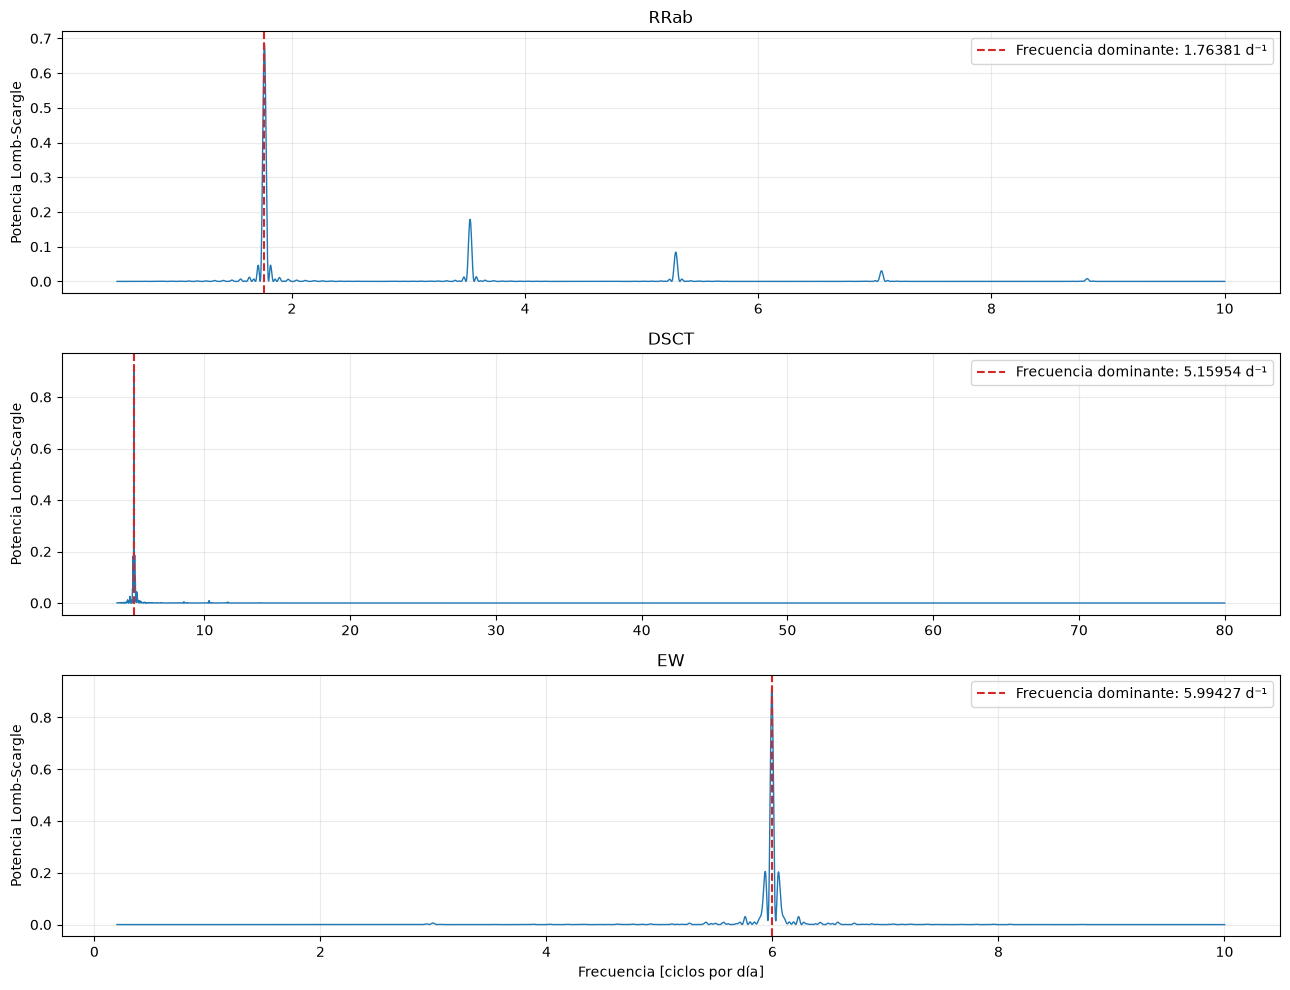

In [42]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 10),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    result = periodogram_results[
        variability_class
    ]

    axis.plot(
        result["frequency"],
        result["power"],
        linewidth=1.0,
    )

    axis.axvline(
        result["dominant_frequency"],
        color="tab:red",
        linestyle="--",
        label=(
            "Frecuencia dominante: "
            f"{result['dominant_frequency']:.5f} d⁻¹"
        ),
    )

    axis.set_title(variability_class)
    axis.set_ylabel("Potencia Lomb-Scargle")
    axis.grid(alpha=0.25)
    axis.legend()

axes[-1].set_xlabel(
    "Frecuencia [ciclos por día]"
)

plt.tight_layout()
plt.show()

In [43]:
period_summary_path = (
    project_root
    / "08_results"
    / "tables"
    / "pilot_period_summary.csv"
)

period_summary.to_csv(
    period_summary_path,
    index=False,
)

print("Resumen guardado:", period_summary_path)
print("Archivo existente:", period_summary_path.exists())

Resumen guardado: C:\Users\Maor\Documents\TESS_Dynamical_Equations\08_results\tables\pilot_period_summary.csv
Archivo existente: True


In [45]:
def phase_fold(
    time_values,
    flux_values,
    period,
    reference_time=None,
):
    """
    Pliega una serie temporal usando un periodo dado.

    Retorna fase y flujo ordenados por fase.
    """
    time_values = np.asarray(
        time_values,
        dtype=float,
    )

    flux_values = np.asarray(
        flux_values,
        dtype=float,
    )

    finite_mask = (
        np.isfinite(time_values)
        & np.isfinite(flux_values)
    )

    time_values = time_values[finite_mask]
    flux_values = flux_values[finite_mask]

    if reference_time is None:
        reference_time = time_values[0]

    phase = (
        (time_values - reference_time) / period
    ) % 1.0

    order = np.argsort(phase)

    return phase[order], flux_values[order]

In [46]:
ew_data = clean_pilot_data["EW"]

ew_time = np.asarray(
    ew_data["time"],
    dtype=float,
)

ew_flux = np.asarray(
    ew_data["sap_normalized"],
    dtype=float,
)

ew_dominant_period = float(
    period_summary.loc[
        period_summary["variability_class"] == "EW",
        "dominant_period_days",
    ].iloc[0]
)

ew_double_period = (
    2.0 * ew_dominant_period
)

ew_phase_single, ew_flux_single = phase_fold(
    time_values=ew_time,
    flux_values=ew_flux,
    period=ew_dominant_period,
)

ew_phase_double, ew_flux_double = phase_fold(
    time_values=ew_time,
    flux_values=ew_flux,
    period=ew_double_period,
)

print(
    f"Periodo dominante: "
    f"{ew_dominant_period:.8f} días"
)

print(
    f"Periodo duplicado: "
    f"{ew_double_period:.8f} días"
)

print(
    f"Periodo duplicado: "
    f"{ew_double_period * 24:.6f} horas"
)

Periodo dominante: 0.16682612 días
Periodo duplicado: 0.33365223 días
Periodo duplicado: 8.007654 horas


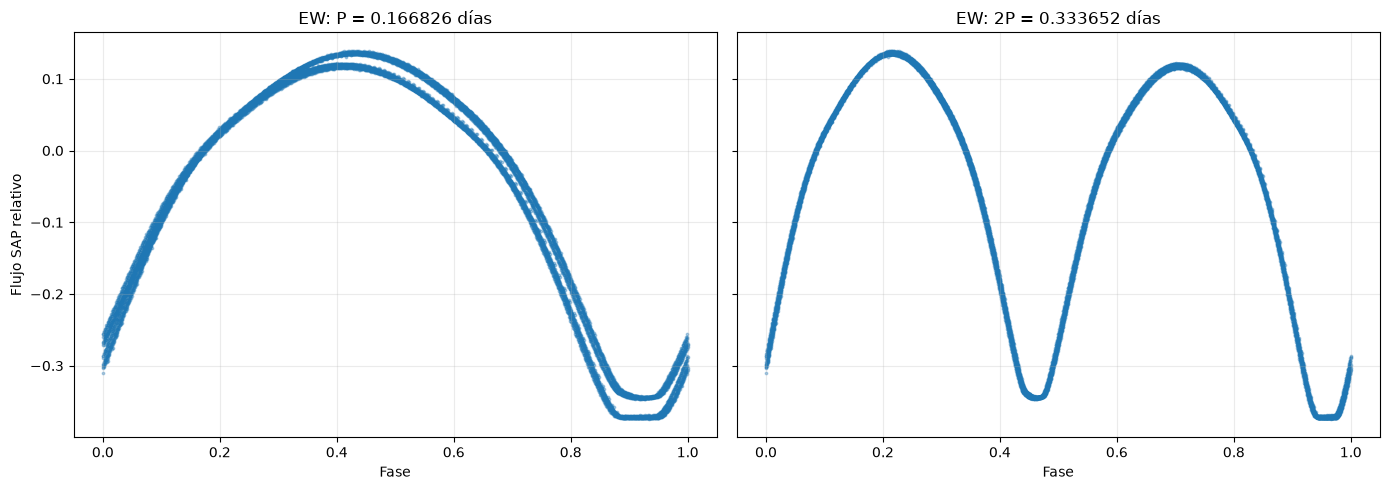

In [47]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
    sharey=True,
)

axes[0].scatter(
    ew_phase_single,
    ew_flux_single,
    s=3,
    alpha=0.35,
)

axes[0].set_title(
    f"EW: P = {ew_dominant_period:.6f} días"
)

axes[0].set_xlabel("Fase")
axes[0].set_ylabel("Flujo SAP relativo")
axes[0].grid(alpha=0.25)

axes[1].scatter(
    ew_phase_double,
    ew_flux_double,
    s=3,
    alpha=0.35,
)

axes[1].set_title(
    f"EW: 2P = {ew_double_period:.6f} días"
)

axes[1].set_xlabel("Fase")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [48]:
def phase_bin_residual_rmse(
    phase,
    flux,
    number_of_bins=100,
):
    """
    Calcula el RMSE respecto de la mediana local en intervalos de fase.
    Un valor menor indica una curva plegada más compacta.
    """
    phase = np.asarray(phase, dtype=float)
    flux = np.asarray(flux, dtype=float)

    bin_edges = np.linspace(
        0.0,
        1.0,
        number_of_bins + 1,
    )

    bin_index = np.digitize(
        phase,
        bin_edges,
    ) - 1

    bin_index = np.clip(
        bin_index,
        0,
        number_of_bins - 1,
    )

    residuals = []

    for current_bin in range(number_of_bins):
        current_mask = (
            bin_index == current_bin
        )

        if current_mask.sum() < 3:
            continue

        current_flux = flux[current_mask]
        local_median = np.median(current_flux)

        residuals.extend(
            current_flux - local_median
        )

    residuals = np.asarray(
        residuals,
        dtype=float,
    )

    return float(
        np.sqrt(np.mean(residuals**2))
    )

In [49]:
ew_rmse_single_period = phase_bin_residual_rmse(
    phase=ew_phase_single,
    flux=ew_flux_single,
    number_of_bins=100,
)

ew_rmse_double_period = phase_bin_residual_rmse(
    phase=ew_phase_double,
    flux=ew_flux_double,
    number_of_bins=100,
)

print(
    "RMSE con periodo dominante:",
    f"{ew_rmse_single_period:.6e}",
)

print(
    "RMSE con periodo duplicado:",
    f"{ew_rmse_double_period:.6e}",
)

print(
    "Razón RMSE 2P / P:",
    f"{ew_rmse_double_period / ew_rmse_single_period:.6f}",
)

RMSE con periodo dominante: 1.427810e-02
RMSE con periodo duplicado: 7.891825e-03
Razón RMSE 2P / P: 0.552722


In [50]:
adopted_periods = {
    "RRab": float(
        period_summary.loc[
            period_summary[
                "variability_class"
            ] == "RRab",
            "dominant_period_days",
        ].iloc[0]
    ),
    "DSCT": float(
        period_summary.loc[
            period_summary[
                "variability_class"
            ] == "DSCT",
            "dominant_period_days",
        ].iloc[0]
    ),
    "EW": ew_double_period,
}

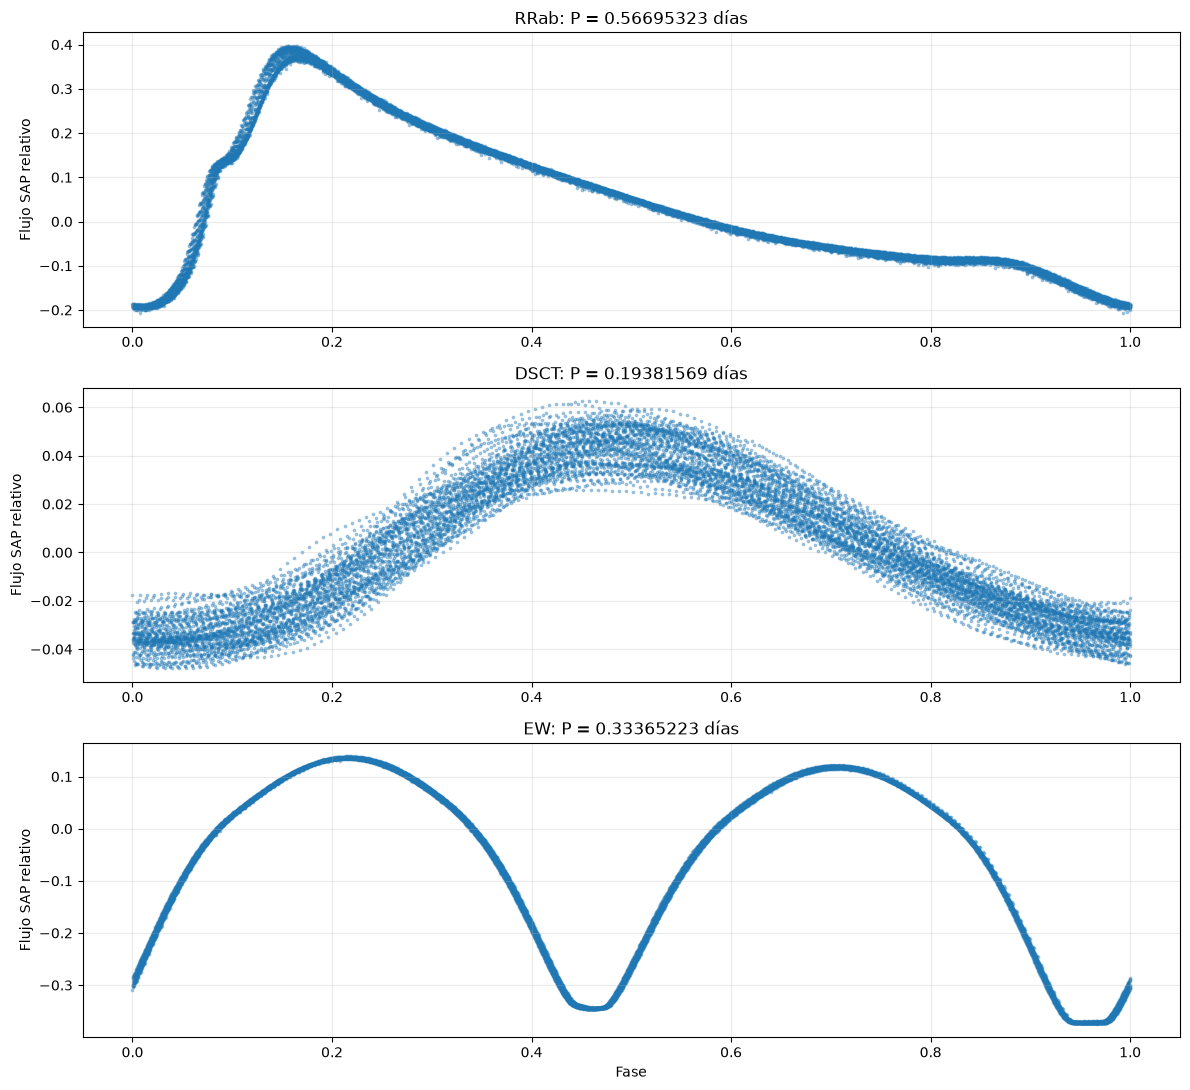

In [51]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 11),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    data = clean_pilot_data[
        variability_class
    ]

    phase, folded_flux = phase_fold(
        time_values=data["time"],
        flux_values=data["sap_normalized"],
        period=adopted_periods[
            variability_class
        ],
    )

    axis.scatter(
        phase,
        folded_flux,
        s=3,
        alpha=0.35,
    )

    axis.set_title(
        f"{variability_class}: "
        f"P = "
        f"{adopted_periods[variability_class]:.8f} días"
    )

    axis.set_ylabel("Flujo SAP relativo")
    axis.grid(alpha=0.25)

axes[-1].set_xlabel("Fase")

plt.tight_layout()
plt.show()

In [52]:
adopted_period_rows = []

for variability_class in [
    "RRab",
    "DSCT",
    "EW",
]:
    lomb_scargle_period = float(
        period_summary.loc[
            period_summary[
                "variability_class"
            ] == variability_class,
            "dominant_period_days",
        ].iloc[0]
    )

    adopted_period = adopted_periods[
        variability_class
    ]

    adopted_period_rows.append(
        {
            "variability_class": (
                variability_class
            ),
            "lomb_scargle_period_days": (
                lomb_scargle_period
            ),
            "adopted_period_days": (
                adopted_period
            ),
            "adopted_period_hours": (
                adopted_period * 24.0
            ),
            "period_multiplier": (
                adopted_period
                / lomb_scargle_period
            ),
            "flux_source": "SAP",
        }
    )

adopted_period_summary = pd.DataFrame(
    adopted_period_rows
)

print(
    adopted_period_summary.to_string(
        index=False
    )
)

variability_class  lomb_scargle_period_days  adopted_period_days  adopted_period_hours  period_multiplier flux_source
             RRab                  0.566953             0.566953             13.606878                1.0         SAP
             DSCT                  0.193816             0.193816              4.651577                1.0         SAP
               EW                  0.166826             0.333652              8.007654                2.0         SAP


In [53]:
adopted_period_path = (
    project_root
    / "08_results"
    / "tables"
    / "pilot_adopted_periods.csv"
)

adopted_period_summary.to_csv(
    adopted_period_path,
    index=False,
)

print(
    "Archivo guardado:",
    adopted_period_path.exists(),
)

Archivo guardado: True


In [54]:
def find_continuous_segments(
    time_values,
    gap_factor=5.0,
):
    """
    Identifica segmentos temporales continuos.

    Un nuevo segmento comienza cuando el intervalo temporal supera
    gap_factor veces la cadencia mediana.
    """
    time_values = np.asarray(
        time_values,
        dtype=float,
    )

    if len(time_values) < 2:
        raise ValueError(
            "Se necesitan al menos dos observaciones."
        )

    time_differences = np.diff(time_values)

    positive_differences = time_differences[
        time_differences > 0
    ]

    median_cadence = np.median(
        positive_differences
    )

    gap_indices = np.flatnonzero(
        time_differences
        > gap_factor * median_cadence
    )

    boundaries = np.concatenate(
        (
            [0],
            gap_indices + 1,
            [len(time_values)],
        )
    )

    segments = []

    for segment_id, (
        start_index,
        end_index,
    ) in enumerate(
        zip(boundaries[:-1], boundaries[1:])
    ):
        segment_time = time_values[
            start_index:end_index
        ]

        if len(segment_time) == 0:
            continue

        segments.append(
            {
                "segment_id": segment_id,
                "start_index": int(start_index),
                "end_index": int(end_index),
                "n_points": int(
                    end_index - start_index
                ),
                "start_time": float(
                    segment_time[0]
                ),
                "end_time": float(
                    segment_time[-1]
                ),
                "duration_days": float(
                    segment_time[-1]
                    - segment_time[0]
                ),
                "median_cadence_seconds": float(
                    median_cadence * 86400.0
                ),
            }
        )

    return segments

In [55]:
segment_rows = []

for variability_class, data in clean_pilot_data.items():
    period_days = adopted_periods[
        variability_class
    ]

    segments = find_continuous_segments(
        time_values=data["time"],
        gap_factor=5.0,
    )

    for segment in segments:
        segment_rows.append(
            {
                "variability_class": (
                    variability_class
                ),
                **segment,
                "adopted_period_days": (
                    period_days
                ),
                "approximate_cycles": (
                    segment["duration_days"]
                    / period_days
                ),
            }
        )

segment_inventory = pd.DataFrame(
    segment_rows
)

print(
    segment_inventory.to_string(
        index=False
    )
)

variability_class  segment_id  start_index  end_index  n_points  start_time    end_time  duration_days  median_cadence_seconds  adopted_period_days  approximate_cycles
             RRab           0            0       3225      3225 1683.356471 1687.899543       4.543072              120.000271             0.566953            8.013134
             RRab           1         3225       3234         9 1687.910654 1687.921765       0.011111              120.000271             0.566953            0.019598
             RRab           2         3234       3484       250 1687.928710 1688.295377       0.366668              120.000271             0.566953            0.646734
             RRab           3         3484       6370      2886 1688.302322 1692.399555       4.097233              120.000271             0.566953            7.226756
             RRab           4         6370       9189      2819 1692.410666 1696.391233       3.980567              120.000271             0.566953            7

In [56]:
minimum_points = 500
minimum_cycles = 10.0

eligible_segments = segment_inventory[
    (
        segment_inventory["n_points"]
        >= minimum_points
    )
    & (
        segment_inventory["approximate_cycles"]
        >= minimum_cycles
    )
].copy()

if eligible_segments.empty:
    raise RuntimeError(
        "Ningún segmento cumple los criterios mínimos."
    )

selected_segments = (
    eligible_segments
    .sort_values(
        [
            "variability_class",
            "duration_days",
            "n_points",
        ],
        ascending=[True, False, False],
    )
    .groupby(
        "variability_class",
        as_index=False,
    )
    .first()
)

selected_segments = selected_segments[
    [
        "variability_class",
        "segment_id",
        "start_index",
        "end_index",
        "n_points",
        "duration_days",
        "median_cadence_seconds",
        "adopted_period_days",
        "approximate_cycles",
    ]
]

print(
    selected_segments.to_string(
        index=False
    )
)

variability_class  segment_id  start_index  end_index  n_points  duration_days  median_cadence_seconds  adopted_period_days  approximate_cycles
             DSCT           2         4791       9426      4635       6.436076              119.999581             0.193816           33.207198
               EW           2         2425       7013      4588       6.373744              120.001877             0.333652           19.102956


In [64]:
import numpy as np
import pandas as pd

selected_trajectories = {}

trajectory_output_directory = (
    project_root
    / "07_data"
    / "processed"
    / "pilot_continuous_segments"
)

trajectory_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

for row in selected_segments.itertuples(index=False):
    variability_class = row.variability_class

    data = clean_pilot_data[variability_class]

    start_index = int(row.start_index)
    end_index = int(row.end_index)

    absolute_time = np.asarray(
        data["time"][start_index:end_index],
        dtype=float,
    )

    relative_time = absolute_time - absolute_time[0]

    sap_flux = np.asarray(
        data["sap_normalized"][start_index:end_index],
        dtype=float,
    )

    selected_trajectories[variability_class] = {
        "time_btjd": absolute_time,
        "time_relative_days": relative_time,
        "sap_normalized": sap_flux,
        "period_days": adopted_periods[variability_class],
    }

    # CORRECCIÓN 1: Se añade la coma que faltaba al final de la línea de 'time_relative_days'
    trajectory_table = pd.DataFrame(
        {
            "time_btjd": absolute_time,
            "time_relative_days": relative_time,
            "sap_normalized": sap_flux,
        }
    )

    output_path = trajectory_output_directory / (
        f"{variability_class.lower()}_continuous_segment.csv"
    )

    trajectory_table.to_csv(
        output_path,
        index=False,
    )

    # CORRECCIÓN 2: Se arreglan las comillas internas del f-string y se remueve la coma final vacía
    print(
        variability_class,
        "| puntos:",
        len(trajectory_table),
        "| duración:",
        f"{relative_time[-1]:.6f} días",
        "| ciclos:",
        f"{relative_time[-1] / adopted_periods[variability_class]:.2f}",
        "| guardado en:",
        output_path.name,
    )


DSCT | puntos: 4635 | duración: 6.436076 días | ciclos: 33.21 | guardado en: dsct_continuous_segment.csv
EW | puntos: 4588 | duración: 6.373744 días | ciclos: 19.10 | guardado en: ew_continuous_segment.csv


In [67]:
trajectory_quality_rows = []

for variability_class, trajectory in (
    selected_trajectories.items()
):
    time_values = trajectory[
        "time_relative_days"
    ]

    time_differences = np.diff(
        time_values
    )

    median_cadence = np.median(
        time_differences
    )

    largest_interval = np.max(
        time_differences
    )

    trajectory_quality_rows.append(
        {
            "variability_class": (
                variability_class
            ),
            "n_points": len(time_values),
            "duration_days": float(
                time_values[-1]
            ),
            "median_cadence_seconds": float(
                median_cadence * 86400.0
            ),
            "largest_interval_seconds": float(
                largest_interval * 86400.0
            ),
            "largest_to_median_ratio": float(
                largest_interval
                / median_cadence
            ),
        }
    )

trajectory_quality_summary = pd.DataFrame(
    trajectory_quality_rows
)

print(
    trajectory_quality_summary.to_string(
        index=False
    )
)

variability_class  n_points  duration_days  median_cadence_seconds  largest_interval_seconds  largest_to_median_ratio
             DSCT      4635       6.436076              119.999219                120.000708                 1.000012
               EW      4588       6.373744              120.002641                240.004518                 1.999994


KeyError: 'RRab'

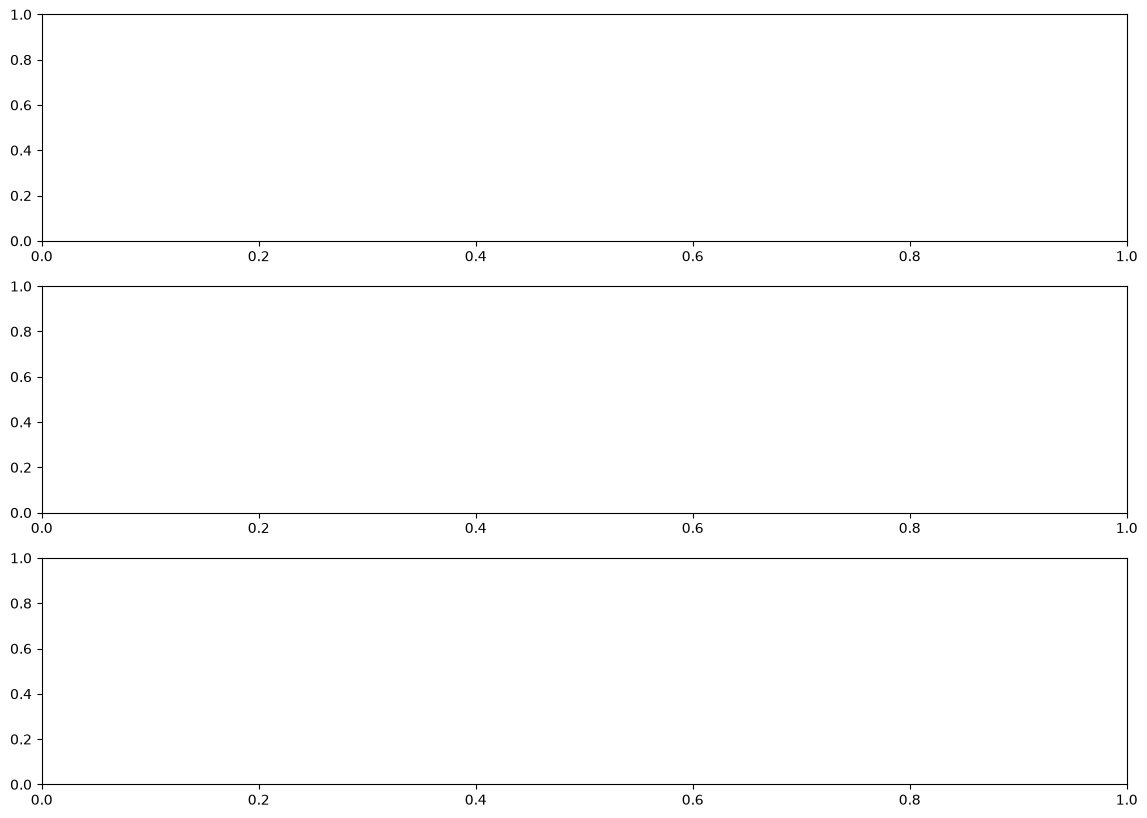

In [68]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 10),
)

for axis, variability_class in zip(
    axes,
    ["RRab", "DSCT", "EW"],
):
    trajectory = selected_trajectories[
        variability_class
    ]

    axis.plot(
        trajectory["time_relative_days"],
        trajectory["sap_normalized"],
        linewidth=0.8,
    )

    axis.set_title(
        f"{variability_class}: "
        "trayectoria continua seleccionada"
    )

    axis.set_ylabel("Flujo SAP relativo")
    axis.grid(alpha=0.25)

axes[-1].set_xlabel(
    "Tiempo desde el inicio del segmento [días]"
)

plt.tight_layout()
plt.show()